In [ ]:
!pip install sentence-transformers scikit-learn gensim matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 57.8 MB/s eta 0:00:00


In [ ]:
!pip install datasets

In [ ]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer
from gensim.models import Word2Vec
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

In [ ]:
from datasets import load_dataset

dataset = load_dataset("ag_news")

texts = dataset["train"]["text"][:100]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

In [ ]:
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(texts)

tfidf_sim = cosine_similarity(tfidf_matrix)

print("TF-IDF Similarity Matrix:\n")
print(tfidf_sim)

TF-IDF Similarity Matrix:

[[1.         0.05435171 0.08338561 ... 0.05581028 0.04244239 0.00551044]
 [0.05435171 1.         0.09757714 ... 0.07701163 0.05273663 0.01456745]
 [0.08338561 0.09757714 1.         ... 0.0482743  0.06164067 0.03580772]
 ...
 [0.05581028 0.07701163 0.0482743  ... 1.         0.08155843 0.02662009]
 [0.04244239 0.05273663 0.06164067 ... 0.08155843 1.         0.0487365 ]
 [0.00551044 0.01456745 0.03580772 ... 0.02662009 0.0487365  1.        ]]


In [ ]:
# Токенизация
tokenized = [text.lower().split() for text in texts]

# Обучение модели
w2v_model = Word2Vec(tokenized, vector_size=100, window=5, min_count=1)

# Получение вектора текста (усреднение слов)
def get_vector(text):
    words = text.lower().split()
    vectors = [w2v_model.wv[word] for word in words if word in w2v_model.wv]
    return np.mean(vectors, axis=0)

w2v_vectors = np.array([get_vector(t) for t in texts])

w2v_sim = cosine_similarity(w2v_vectors)

print("Word2Vec Similarity Matrix:\n")
print(w2v_sim)

Word2Vec Similarity Matrix:

[[0.99999994 0.694581   0.69246143 ... 0.55647147 0.5617121  0.5780696 ]
 [0.694581   1.0000001  0.68113095 ... 0.596589   0.6980337  0.7137427 ]
 [0.69246143 0.68113095 0.99999994 ... 0.59071153 0.64624405 0.6853882 ]
 ...
 [0.55647147 0.596589   0.59071153 ... 0.99999994 0.5542622  0.6476885 ]
 [0.5617121  0.6980337  0.64624405 ... 0.5542622  0.9999997  0.69168925]
 [0.5780696  0.7137427  0.6853882  ... 0.6476885  0.69168925 0.9999998 ]]


In [ ]:
model = SentenceTransformer('all-MiniLM-L6-v2')

sbert_embeddings = model.encode(texts)

sbert_sim = cosine_similarity(sbert_embeddings)

print("SBERT Similarity Matrix:\n")
print(sbert_sim)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

SBERT Similarity Matrix:

[[ 1.0000004   0.24643776  0.26185894 ...  0.08342385 -0.00698232
   0.10908978]
 [ 0.24643776  0.9999998   0.27115288 ...  0.17397758  0.03576809
   0.17445157]
 [ 0.26185894  0.27115288  1.0000002  ...  0.11321302 -0.06189311
   0.11361326]
 ...
 [ 0.08342385  0.17397758  0.11321302 ...  1.0000004  -0.03573918
   0.02595293]
 [-0.00698232  0.03576809 -0.06189311 ... -0.03573918  1.0000001
   0.17020412]
 [ 0.10908978  0.17445157  0.11361326 ...  0.02595293  0.17020412
   1.0000002 ]]


In [ ]:
def check_plagiarism(sim_matrix, threshold=0.8):
    n = len(sim_matrix)
    for i in range(n):
        for j in range(i+1, n):
            score = sim_matrix[i][j]

            if score > threshold:
                status = "Plagiarism"
            elif score > 0.5:
                status = "Similar"
            else:
                status = "Different"

            print(f"Text {i} vs Text {j}: {score:.2f} -> {status}")

print("SBERT Plagiarism Check:\n")
check_plagiarism(sbert_sim)

SBERT Plagiarism Check:

Text 0 vs Text 1: 0.25 -> Different
Text 0 vs Text 2: 0.26 -> Different
Text 0 vs Text 3: 0.06 -> Different
Text 0 vs Text 4: 0.15 -> Different
Text 0 vs Text 5: 0.25 -> Different
Text 0 vs Text 6: 0.13 -> Different
Text 0 vs Text 7: 0.18 -> Different
Text 0 vs Text 8: -0.02 -> Different
Text 0 vs Text 9: 0.94 -> Plagiarism
Text 0 vs Text 10: 0.23 -> Different
Text 0 vs Text 11: 0.13 -> Different
Text 0 vs Text 12: 0.05 -> Different
Text 0 vs Text 13: 0.23 -> Different
Text 0 vs Text 14: 0.21 -> Different
Text 0 vs Text 15: 0.04 -> Different
Text 0 vs Text 16: 0.03 -> Different
Text 0 vs Text 17: 0.17 -> Different
Text 0 vs Text 18: 0.07 -> Different
Text 0 vs Text 19: 0.21 -> Different
Text 0 vs Text 20: 0.19 -> Different
Text 0 vs Text 21: 0.06 -> Different
Text 0 vs Text 22: 0.01 -> Different
Text 0 vs Text 23: 0.12 -> Different
Text 0 vs Text 24: 0.13 -> Different
Text 0 vs Text 25: 0.09 -> Different
Text 0 vs Text 26: 0.21 -> Different
Text 0 vs Text 27: 0

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42)
clusters = kmeans.fit_predict(sbert_embeddings)

for i, text in enumerate(texts):
    print(f"Text {i}: Cluster {clusters[i]}")

Text 0: Cluster 2
Text 1: Cluster 3
Text 2: Cluster 2
Text 3: Cluster 2
Text 4: Cluster 2
Text 5: Cluster 2
Text 6: Cluster 2
Text 7: Cluster 2
Text 8: Cluster 1
Text 9: Cluster 2
Text 10: Cluster 2
Text 11: Cluster 2
Text 12: Cluster 2
Text 13: Cluster 3
Text 14: Cluster 2
Text 15: Cluster 0
Text 16: Cluster 0
Text 17: Cluster 2
Text 18: Cluster 2
Text 19: Cluster 2
Text 20: Cluster 3
Text 21: Cluster 2
Text 22: Cluster 2
Text 23: Cluster 2
Text 24: Cluster 2
Text 25: Cluster 2
Text 26: Cluster 3
Text 27: Cluster 2
Text 28: Cluster 0
Text 29: Cluster 1
Text 30: Cluster 2
Text 31: Cluster 3
Text 32: Cluster 2
Text 33: Cluster 1
Text 34: Cluster 1
Text 35: Cluster 2
Text 36: Cluster 3
Text 37: Cluster 0
Text 38: Cluster 3
Text 39: Cluster 1
Text 40: Cluster 3
Text 41: Cluster 2
Text 42: Cluster 1
Text 43: Cluster 1
Text 44: Cluster 1
Text 45: Cluster 3
Text 46: Cluster 2
Text 47: Cluster 1
Text 48: Cluster 0
Text 49: Cluster 0
Text 50: Cluster 1
Text 51: Cluster 1
Text 52: Cluster 0
Tex

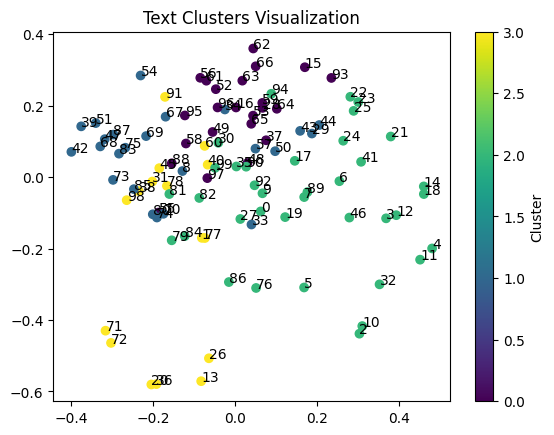

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
reduced = pca.fit_transform(sbert_embeddings)

plt.figure()

scatter = plt.scatter(
    reduced[:, 0],
    reduced[:, 1],
    c=clusters,
)

for i in range(len(texts)):
    plt.annotate(i, (reduced[i, 0], reduced[i, 1]))

plt.title("Text Clusters Visualization")

plt.colorbar(scatter, label="Cluster")

plt.show()

In [ ]:
import pandas as pd

def create_comparison_table(sim_matrices, method_names):
    results = []

    n = len(sim_matrices[0])

    for i in range(n):
        for j in range(i+1, n):
            row = {
                "Text Pair": f"{i}-{j}"
            }
            for name, sim in zip(method_names, sim_matrices):
                row[name] = round(sim[i][j], 3)
            results.append(row)

    df = pd.DataFrame(results)
    return df

df_compare = create_comparison_table(
    [tfidf_sim, w2v_sim, sbert_sim],
    ["TF-IDF", "Word2Vec", "SBERT"]
)

df_compare

,Text Pair,TF-IDF,Word2Vec,SBERT
0,0-1,0.054,0.695,0.246
1,0-2,0.083,0.692,0.262
2,0-3,0.041,0.530,0.060
3,0-4,0.002,0.529,0.148
4,0-5,0.042,0.604,0.254
...,...,...,...,...
4945,96-98,0.080,0.615,0.107
4946,96-99,0.051,0.719,0.046
4947,97-98,0.082,0.554,-0.036
4948,97-99,0.027,0.648,0.026


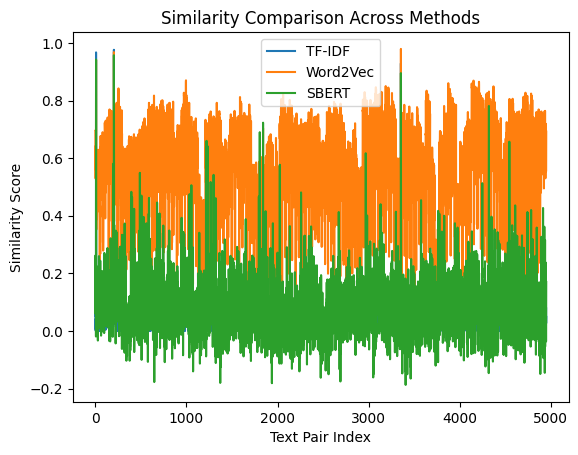

In [ ]:
plt.figure()

plt.plot(df_compare["TF-IDF"], label="TF-IDF")
plt.plot(df_compare["Word2Vec"], label="Word2Vec")
plt.plot(df_compare["SBERT"], label="SBERT")

plt.legend()
plt.title("Similarity Comparison Across Methods")
plt.xlabel("Text Pair Index")
plt.ylabel("Similarity Score")

plt.show()

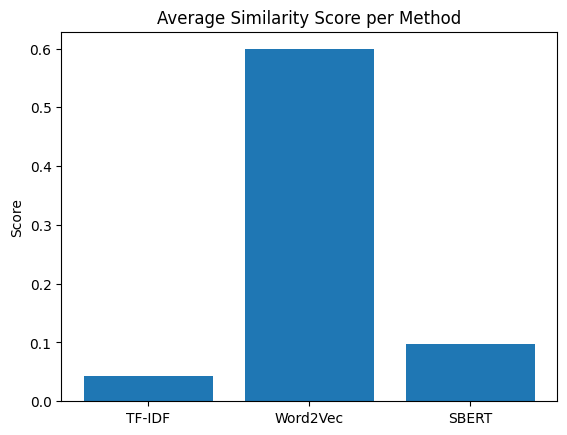

In [ ]:
avg_scores = [
    np.mean(tfidf_sim),
    np.mean(w2v_sim),
    np.mean(sbert_sim)
]

methods = ["TF-IDF", "Word2Vec", "SBERT"]

plt.figure()
plt.bar(methods, avg_scores)

plt.title("Average Similarity Score per Method")
plt.ylabel("Score")

plt.show()

In [ ]:
def show_top_similar(sim_matrix, texts):
    n = len(sim_matrix)

    for i in range(n):
        similarities = list(enumerate(sim_matrix[i]))
        similarities = sorted(similarities, key=lambda x: x[1], reverse=True)

        print(f"\nText {i}: {texts[i]}")
        print("Most similar:")

        for idx, score in similarities[1:3]:
            print(f"  -> Text {idx} ({score:.2f})")

print("Top Similar Texts (SBERT):")
show_top_similar(sbert_sim, texts)

Top Similar Texts (SBERT):

Text 0: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
Most similar:
  -> Text 9 (0.94)
  -> Text 2 (0.26)

Text 1: Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, has quietly placed\its bets on another part of the market.
Most similar:
  -> Text 71 (0.32)
  -> Text 36 (0.29)

Text 2: Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over the stock market next week during the depth of the\summer doldrums.
Most similar:
  -> Text 10 (0.96)
  -> Text 5 (0.58)

Text 3: Iraq Halts Oil Exports from Main Southern Pipeline (Reuters) Reuters - Authorities have halted oil export\flows from the main pipelin

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

params = [
    {"ngram_range": (1,1)},
    {"ngram_range": (1,2)},
    {"ngram_range": (1,3)}
]

results = []

for p in params:
    tfidf = TfidfVectorizer(ngram_range=p["ngram_range"])
    matrix = tfidf.fit_transform(texts)
    sim = cosine_similarity(matrix)

    avg_score = np.mean(sim)

    results.append({
        "ngram_range": str(p["ngram_range"]),
        "avg_similarity": avg_score
    })

import pandas as pd
df_tfidf_params = pd.DataFrame(results)
df_tfidf_params

,ngram_range,avg_similarity
0,"(1, 1)",0.043704
1,"(1, 2)",0.027047
2,"(1, 3)",0.021373


In [ ]:
from gensim.models import Word2Vec
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

def get_vector(text, model):
    words = text.lower().split()
    vectors = [model.wv[word] for word in words if word in model.wv]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


params = [50, 100, 200]

results = []

for size in params:
    model = Word2Vec(
        tokenized,
        vector_size=size,
        window=5,
        min_count=1
    )

    vectors = np.array([get_vector(t, model) for t in texts])

    sim = cosine_similarity(vectors)

    avg_score = np.mean(sim)

    results.append({
        "vector_size": size,
        "avg_similarity": avg_score
    })

df_w2v_params = pd.DataFrame(results)

df_w2v_params

,vector_size,avg_similarity
0,50,0.594864
1,100,0.598702
2,200,0.593514


In [ ]:
models = [
    "all-MiniLM-L6-v2",
    "paraphrase-MiniLM-L3-v2"
]

results = []

for m in models:
    model = SentenceTransformer(m)
    emb = model.encode(texts)

    sim = cosine_similarity(emb)
    avg_score = np.mean(sim)

    results.append({
        "model": m,
        "avg_similarity": avg_score
    })

df_sbert_params = pd.DataFrame(results)
df_sbert_params

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/paraphrase-MiniLM-L3-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,model,avg_similarity
0,all-MiniLM-L6-v2,0.097014
1,paraphrase-MiniLM-L3-v2,0.074061
